In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, root_mean_squared_error
from scipy import stats

# 데이터 준비

In [2]:
df = pd.read_csv("./data/auto-mpg.csv", header = None)

In [3]:
df.columns = ["mpg", "cylinders", "displacement", "horsepower", "weight", "acceleration",
              "model_year", "origin", "name"]

In [4]:
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,ford torino


# 데이터 탐색

In [5]:
df.shape

(398, 9)

In [6]:
df.dtypes

mpg             float64
cylinders         int64
displacement    float64
horsepower       object
weight          float64
acceleration    float64
model_year        int64
origin            int64
name             object
dtype: object

In [7]:
df["horsepower"].unique()

array(['130.0', '165.0', '150.0', '140.0', '198.0', '220.0', '215.0',
       '225.0', '190.0', '170.0', '160.0', '95.00', '97.00', '85.00',
       '88.00', '46.00', '87.00', '90.00', '113.0', '200.0', '210.0',
       '193.0', '?', '100.0', '105.0', '175.0', '153.0', '180.0', '110.0',
       '72.00', '86.00', '70.00', '76.00', '65.00', '69.00', '60.00',
       '80.00', '54.00', '208.0', '155.0', '112.0', '92.00', '145.0',
       '137.0', '158.0', '167.0', '94.00', '107.0', '230.0', '49.00',
       '75.00', '91.00', '122.0', '67.00', '83.00', '78.00', '52.00',
       '61.00', '93.00', '148.0', '129.0', '96.00', '71.00', '98.00',
       '115.0', '53.00', '81.00', '79.00', '120.0', '152.0', '102.0',
       '108.0', '68.00', '58.00', '149.0', '89.00', '63.00', '48.00',
       '66.00', '139.0', '103.0', '125.0', '133.0', '138.0', '135.0',
       '142.0', '77.00', '62.00', '132.0', '84.00', '64.00', '74.00',
       '116.0', '82.00'], dtype=object)

In [8]:
df = df[df["horsepower"] != "?"]

In [9]:
df.shape

(392, 9)

In [11]:
df["horsepower"] = df["horsepower"].astype(float)

In [12]:
df.dtypes

mpg             float64
cylinders         int64
displacement    float64
horsepower      float64
weight          float64
acceleration    float64
model_year        int64
origin            int64
name             object
dtype: object

In [24]:
df.describe()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin
count,392.000000,392.000000,392.000000,392.000000,392.000000,392.000000,392.000000,392.000000
mean,23.445918,5.471939,194.411990,104.469388,2977.584184,15.541327,75.979592,1.576531
std,7.805007,1.705783,104.644004,38.491160,849.402560,2.758864,3.683737,0.805518
min,9.000000,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000,1.000000
25%,17.000000,4.000000,105.000000,75.000000,2225.250000,13.775000,73.000000,1.000000
50%,22.750000,4.000000,151.000000,93.500000,2803.500000,15.500000,76.000000,1.000000
75%,29.000000,8.000000,275.750000,126.000000,3614.750000,17.025000,79.000000,2.000000
max,46.600000,8.000000,455.000000,230.000000,5140.000000,24.800000,82.000000,3.000000


# 변수 선택

In [13]:
# 분석에 활용할 열 선택(연비, 실린더, 출력, 중량)
ndf = df[["mpg", "cylinders", "horsepower", "weight"]]

In [14]:
ndf.head()

,mpg,cylinders,horsepower,weight
0,18.0,8,130.0,3504.0
1,15.0,8,165.0,3693.0
2,18.0,8,150.0,3436.0
3,16.0,8,150.0,3433.0
4,17.0,8,140.0,3449.0


# 데이터셋 분할

In [15]:
x = ndf.drop("mpg", axis = 1)
y = ndf["mpg"]

In [16]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.3, random_state = 23)

In [17]:
print(x_train.shape, x_test.shape)

(274, 3) (118, 3)


# 선형 회귀 모델

In [18]:
lr = LinearRegression()

In [19]:
lr.fit(x_train, y_train)

LinearRegression()

In [20]:
# 결정계수
r_square = lr.score(x_test, y_test)

In [21]:
r_square

0.6533059000280043

In [23]:
x_train.head()

,cylinders,horsepower,weight
85,8,175.0,4100.0
65,8,153.0,4129.0
16,6,97.0,2774.0
78,4,87.0,2979.0
190,8,152.0,4215.0


In [22]:
lr.coef_, lr.intercept_

(array([-0.43494265, -0.04591132, -0.00555456]), 47.477278829077605)

In [25]:
y_pred = lr.predict(x_test)

In [26]:
mse = mean_squared_error(y_test, y_pred)

In [27]:
mse

16.0487370543004

In [29]:
rmse = root_mean_squared_error(y_test, y_pred)

In [30]:
rmse

4.006087499581156

In [31]:
pd.DataFrame({"ans" : y_test, "pred" : y_pred})

,ans,pred
118,24.0,30.307413
328,30.0,24.609121
102,26.0,32.794190
276,21.6,24.932704
315,24.3,24.925138
...,...,...
150,26.0,28.186796
169,20.0,24.090495
316,19.1,21.955628
300,23.9,20.869115


## 모델 평가 시각화

### 예측값과 정답값 비교 산점도

- 모델의 예측이 실제값과 얼마나 밀접하게 일치하는지 평가

- 완벽한 모델은 모든 점이 대각선 위에 놓여 있는 것

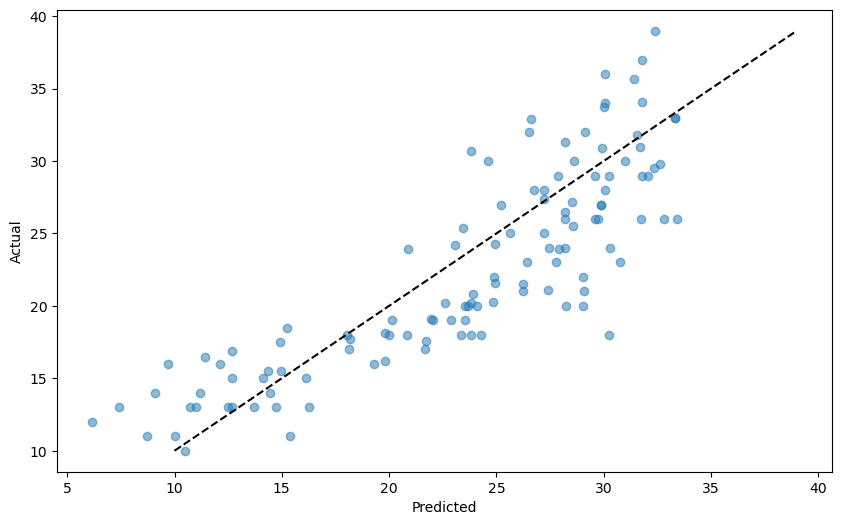

In [32]:
plt.figure(figsize = (10, 6))

plt.scatter(y_pred, y_test, alpha = 0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "k--")

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

### 잔차도

- 잔차의 패턴을 식별하는 데 도움

- 이상적으로는 잔차가 0 주위에 무작위로 흩어져 있어야 하며, 이는 모델의 오류가 무작위임을 나타냄

In [33]:
# 잔차
residuals = y_test - y_pred

In [34]:
residuals

118   -6.307413
328    5.390879
102   -6.794190
276   -3.332704
315   -0.625138
         ...   
150   -2.186796
169   -4.090495
316   -2.855628
300    3.030885
19    -7.432965
Name: mpg, Length: 118, dtype: float64

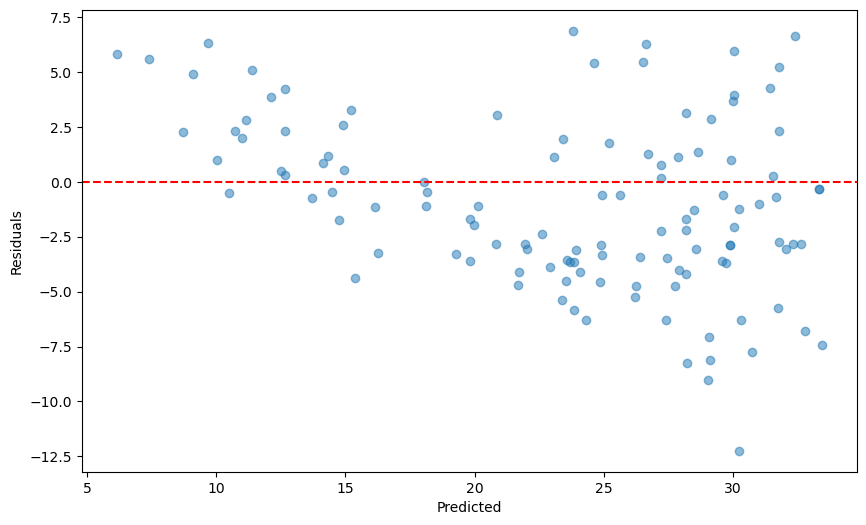

In [35]:
plt.figure(figsize = (10, 6))

plt.scatter(y_pred, residuals, alpha = 0.5)
plt.axhline(y = 0, color = "r", linestyle = "--")

plt.xlabel("Predicted")
plt.ylabel("Residuals")
plt.show()

### QQ plot

- 잔차 분포를 정규 분포와 비교

- 잘 맞는 모델에서는 점들이 대략 대각선을 따라 위치해야 함

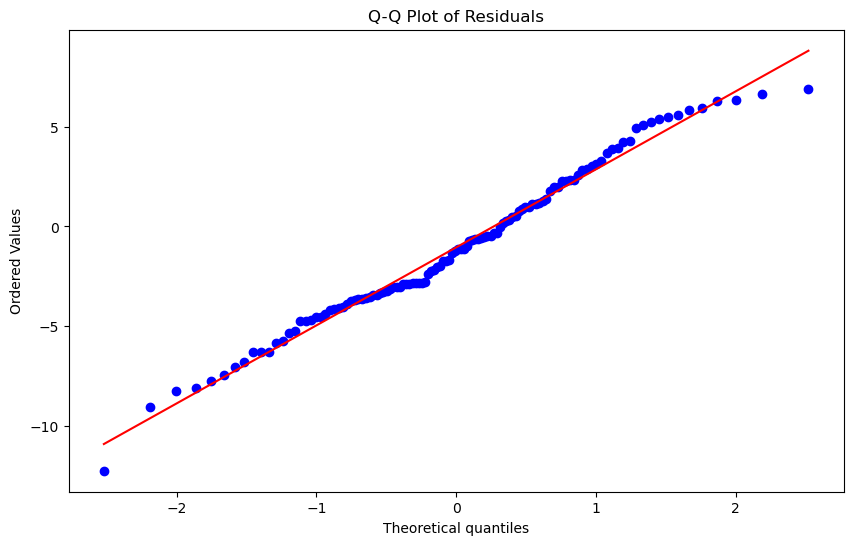

In [36]:
plt.figure(figsize = (10, 6))

stats.probplot(residuals.values.flatten(), dist = "norm", plot = plt)

plt.title("Q-Q Plot of Residuals")
plt.show()

### 잔차 히스토그램

- 잔차의 분포에 대한 또 다른 시각을 제공

- 잘 맞는 모델의 경우 0을 중심으로 하는 정규 분포를 볼 수 있음

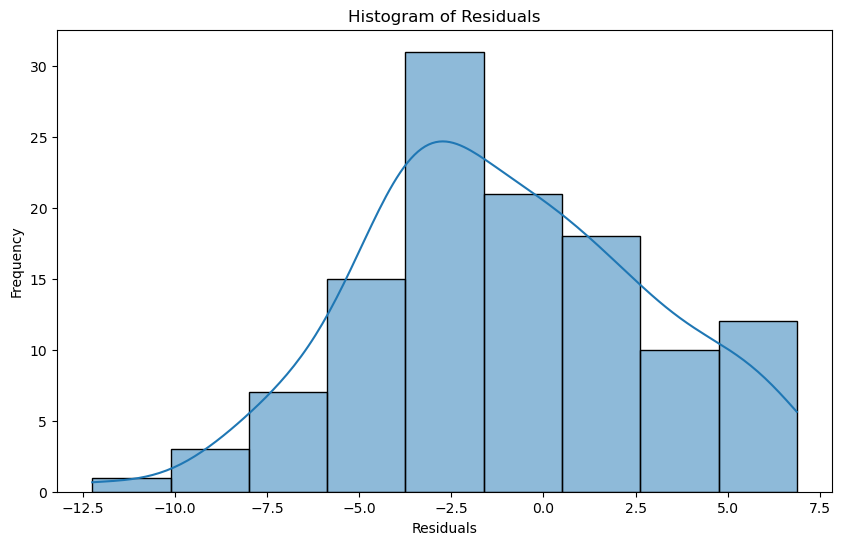

In [37]:
plt.figure(figsize = (10, 6))

sns.histplot(residuals, kde = True)

plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.title("Histogram of Residuals")
plt.show()